# CSET343 – AI in Healthcare
## Lab Assignment 8: NLP on Health-Related News Headlines (Topic Modeling)

**Dataset:** Adult Immunization News Headlines (`Adult_Immunization_News_Headlines.csv`) — Date, Source, Headlines, Teaser columns.




### Setup — Install Required Packages

In [1]:

!pip install -q nltk wordcloud gensim pyLDAvis scikit-learn pandas numpy matplotlib seaborn


In [2]:
import re
import string
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud

import gensim
from gensim import corpora
from gensim.models import LdaModel

import pyLDAvis
import pyLDAvis.gensim_models

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42


In [3]:
# One-time NLTK resource downloads
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/pankurajasaivardhan/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/pankurajasaivardhan/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/pankurajasaivardhan/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/pankurajasaivardhan/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/pankurajasaivardhan/nltk_data...
[nltk_data] Integrity check failed for 'omw-1.4': size mismatch (got
[nltk_data]     360448, expected 26634772)


False


## Task 1: Data Preprocessing and Cleaning


### 1.1 Load the Dataset

In [4]:

DATA_PATH = "Adult_Immunization_News_Headlines.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (1482, 4)


,Date,Source,Headlines,Teaser
0,July 2007,Medscape Medical News,CDC Issues New Guidelines for Meningococcal Va...,The Centers for Disease Control and Prevention...
1,June 2006,Medscape Medical News,FDA Approves First Cervical Cancer Vaccine,Applauded as one of the most important advance...
2,February 2005,Medscape Medical News,Highlights From MMWR: CDC Reports on Imported ...,The CDC has reported on a case of imported vac...
3,October 2005,Medscape Medical News,Menactra May be Linked to Cases of Guillain-Ba...,The FDA and CDC investigate 5 cases of GBS in ...
4,February 2004,Medscape Medical News,Renal Tumor Cell Vaccine After Radical Nephrec...,"However, editorialists urge caution in face of..."


In [5]:
df.info()
print("\nMissing values per column:\n", df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1482 entries, 0 to 1481
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       1482 non-null   object
 1   Source     1482 non-null   object
 2   Headlines  1482 non-null   object
 3   Teaser     1482 non-null   object
dtypes: object(4)
memory usage: 46.4+ KB

Missing values per column:
 Date         0
Source       0
Headlines    0
Teaser       0
dtype: int64


In [6]:
# Combine Headlines + Teaser into a single text field (more content = better topic modeling)
df["Headlines"] = df["Headlines"].fillna("")
df["Teaser"] = df["Teaser"].fillna("")
df["text"] = (df["Headlines"] + ". " + df["Teaser"]).str.strip()

# Drop rows that end up with no usable text
df = df[df["text"].str.len() > 0].reset_index(drop=True)
print("Rows with usable text:", len(df))
df[["Headlines", "Teaser", "text"]].head()


Rows with usable text: 1482


,Headlines,Teaser,text
0,CDC Issues New Guidelines for Meningococcal Va...,The Centers for Disease Control and Prevention...,CDC Issues New Guidelines for Meningococcal Va...
1,FDA Approves First Cervical Cancer Vaccine,Applauded as one of the most important advance...,FDA Approves First Cervical Cancer Vaccine. Ap...
2,Highlights From MMWR: CDC Reports on Imported ...,The CDC has reported on a case of imported vac...,Highlights From MMWR: CDC Reports on Imported ...
3,Menactra May be Linked to Cases of Guillain-Ba...,The FDA and CDC investigate 5 cases of GBS in ...,Menactra May be Linked to Cases of Guillain-Ba...
4,Renal Tumor Cell Vaccine After Radical Nephrec...,"However, editorialists urge caution in face of...",Renal Tumor Cell Vaccine After Radical Nephrec...


### 1.2 Cleaning Pipeline — Lowercasing, Punctuation Removal, Tokenization, Stop-word Removal, Lemmatization

In [7]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# A few domain-generic words that add noise to health-news headlines specifically
extra_stopwords = {"said", "new", "study", "says", "may", "could", "also", "one", "two"}
stop_words = stop_words.union(extra_stopwords)


def clean_and_tokenize(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)          # remove URLs if any
    text = text.translate(str.maketrans("", "", string.punctuation))  # remove punctuation
    text = re.sub(r"\d+", " ", text)                      # remove standalone digits
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha()]            # keep alphabetic tokens only
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens


df["tokens"] = df["text"].apply(clean_and_tokenize)
df["cleaned_text"] = df["tokens"].apply(lambda toks: " ".join(toks))

# Drop rows that became empty after cleaning
df = df[df["tokens"].map(len) > 0].reset_index(drop=True)
print("Rows remaining after cleaning:", len(df))


Rows remaining after cleaning: 1482


### 1.3 Display Cleaned Text Samples

In [8]:
pd.set_option("display.max_colwidth", 100)
df[["Headlines", "cleaned_text"]].sample(10, random_state=RANDOM_STATE)


,Headlines,cleaned_text
123,FDA Commissioner Addresses H1N1 Vaccine Safety Concerns,fda commissioner address vaccine safety concern commissioner food drug administration reassured ...
432,Meningococcal Conjugate Vaccine Appears Safe in Infants,meningococcal conjugate vaccine appears safe infant pooled analysis suggests dose series menacwy...
1031,Should Europe Be Worried About Zika Virus This Summer?,europe worried zika virus summer arrival warm weather mosquito risk zika epidemic europe
529,More Data Showing Flu Vaccine Lowers CVD Risk,data showing flu vaccine lower cvd risk latest report metaanalysis six randomized controlled cli...
1415,New York City Defends Measles Vaccination Order in Court,york city defends measles vaccination order court york city department health defended mandatory...
628,CDC Announces False Alarm on MERS Transmission,cdc announces false alarm mers transmission testing agency concluded illinois man exposed infect...
297,Flu Vaccine Rates Are High for 2 Seasons in a Row,flu vaccine rate high season row cdc vaccine rate still short government longterm goal
1473,California Vaccine Bill Amended to Appease Governor,california vaccine bill amended appease governor vbi vaccine inc monday latestage testing hepati...
67,HPV Vaccination of Males Not Cost-Effective,hpv vaccination male costeffective analysis find vaccinating boy addition girl unlikely costeffe...
49,Nonadjuvanted Influenza Vaccines May Not Protect Against 2009 H1N1,nonadjuvanted influenza vaccine protect vaccination recent seasonal nonadjuvanted influenza vacc...



## Task 2: Exploratory Text Analysis & Word Visualization


### 2.1 Word Frequency Distribution

In [9]:
all_tokens = [tok for toks in df["tokens"] for tok in toks]
word_freq = Counter(all_tokens)

print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(word_freq))
print("\nTop 20 most frequent words:")
for word, count in word_freq.most_common(20):
    print(f"  {word}: {count}")


Total tokens: 31070
Unique tokens: 4912

Top 20 most frequent words:
  vaccine: 1559
  vaccination: 463
  influenza: 394
  flu: 317
  hpv: 280
  child: 258
  disease: 232
  risk: 224
  year: 219
  health: 208
  ebola: 206
  cdc: 182
  virus: 173
  patient: 173
  outbreak: 169
  rate: 142
  trial: 142
  according: 142
  immunization: 140
  adult: 140


### 2.2 Plot Top 20 Frequent Words

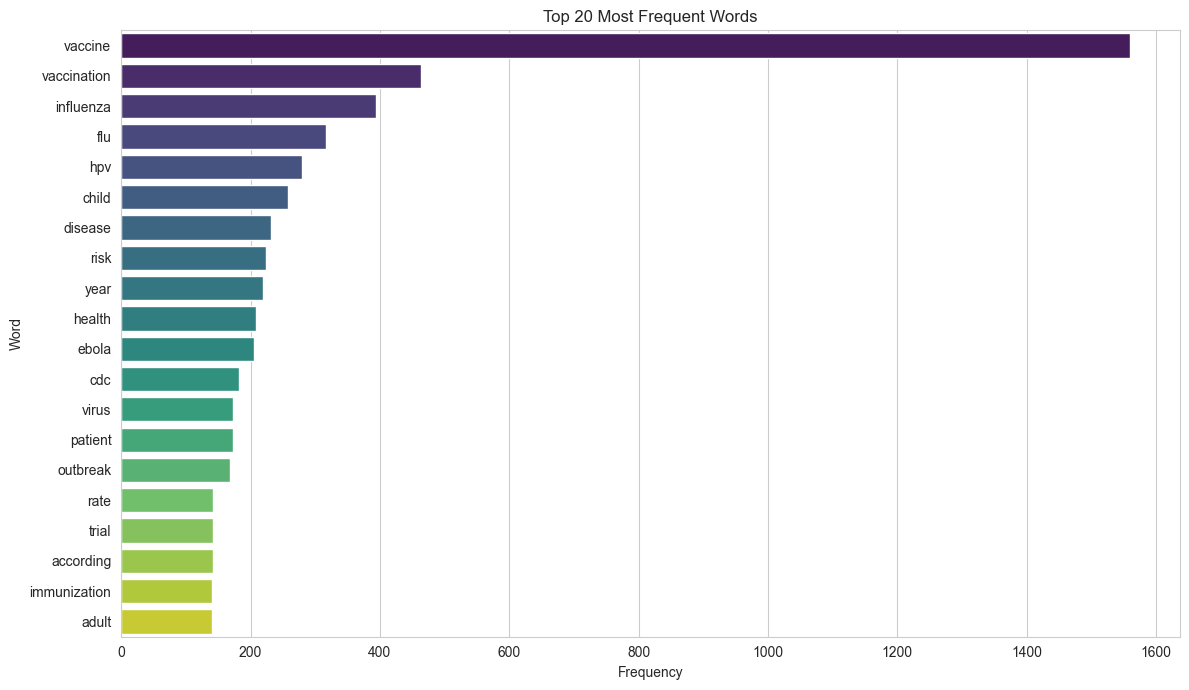

In [10]:
top_20 = word_freq.most_common(20)
top_words, top_counts = zip(*top_20)

plt.figure(figsize=(12, 7))
sns.barplot(x=list(top_counts), y=list(top_words), hue=list(top_words), palette="viridis", legend=False)
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


### 2.3 Word Cloud

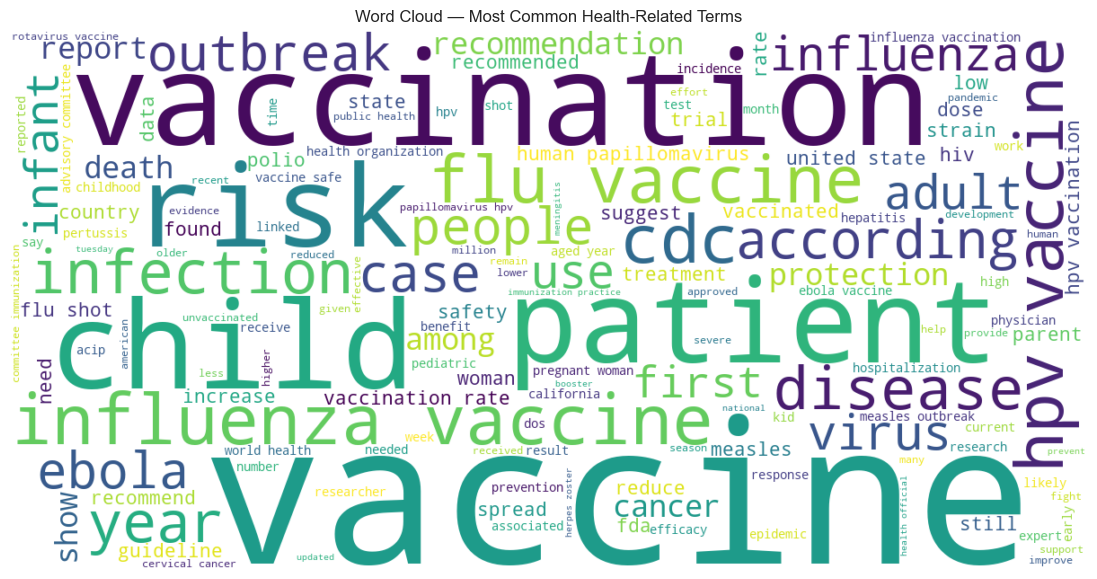

In [11]:
wordcloud_text = " ".join(all_tokens)

wc = WordCloud(
    width=1200, height=600,
    background_color="white",
    colormap="viridis",
    max_words=150,
    random_state=RANDOM_STATE,
).generate(wordcloud_text)

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — Most Common Health-Related Terms")
plt.show()



## Task 3: Topic Modeling using LDA (Latent Dirichlet Allocation)


### 3.1 Build the Dictionary and Corpus

In [12]:
texts = df["tokens"].tolist()

# Build a gensim dictionary, filtering very rare and very common tokens
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=3, no_above=0.6)

corpus = [dictionary.doc2bow(text) for text in texts]

print("Vocabulary size after filtering:", len(dictionary))
print("Number of documents:", len(corpus))


Vocabulary size after filtering: 1649
Number of documents: 1482


### 3.2 Train the LDA Model

In [13]:
NUM_TOPICS = 5

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    random_state=RANDOM_STATE,
    passes=15,
    iterations=100,
    alpha="auto",
    per_word_topics=True,
)


### 3.3 Display Top 5 Words per Topic

In [14]:
for topic_id in range(NUM_TOPICS):
    top_words = lda_model.show_topic(topic_id, topn=5)
    words_str = ", ".join([f"{w} ({p:.3f})" for w, p in top_words])
    print(f"Topic {topic_id}: {words_str}")


Topic 0: vaccination (0.032), risk (0.023), pertussis (0.015), influenza (0.013), patient (0.013)
Topic 1: health (0.020), influenza (0.019), vaccination (0.018), cdc (0.016), case (0.014)
Topic 2: trial (0.027), adult (0.014), dose (0.011), rotavirus (0.011), vaccination (0.011)
Topic 3: hpv (0.035), ebola (0.021), cancer (0.016), human (0.015), vaccination (0.013)
Topic 4: flu (0.034), influenza (0.031), child (0.017), vaccination (0.013), patient (0.013)


In [15]:
# Coherence score — how interpretable/well-separated the discovered topics are
from gensim.models import CoherenceModel

coherence_model = CoherenceModel(model=lda_model, texts=texts, dictionary=dictionary, coherence="c_v")
coherence_score = coherence_model.get_coherence()
print(f"Topic Coherence (c_v): {coherence_score:.4f}")


Topic Coherence (c_v): 0.2551


### 3.4 Visualize with pyLDAvis

In [16]:
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus, dictionary, sort_topics=False)
vis


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.089868  0.109050       1        1  17.948475
1     -0.090382  0.042724       2        1  26.762514
2      0.121846 -0.125173       3        1  15.638022
3     -0.153260 -0.054877       4        1  18.464841
4      0.031928  0.028276       5        1  21.186147, topic_info=           Term        Freq       Total Category  logprob  loglift
65        trial  133.000000  133.000000  Default  30.0000  30.0000
278         hpv  265.000000  265.000000  Default  29.0000  29.0000
79          flu  297.000000  297.000000  Default  28.0000  28.0000
39    influenza  369.000000  369.000000  Default  27.0000  27.0000
157   pertussis   68.000000   68.000000  Default  26.0000  26.0000
..          ...         ...         ...      ...      ...      ...
88     seasonal   21.436154   57.842468   Topic5  -5.5145   0.5592
89       strain   21.110024   56.764000   Topic5  -5.5298   0.5627
65        trial   25.367897  133.485039   Topic5  -5.3461  -0.1087
181       adult   24.354915  131.897681   Topic5  -5.3869  -0.1375
194  researcher   21.721391   70.558255   Topic5  -5.5013   0.3737

[370 rows x 6 columns], token_table=      Topic      Freq         Term
term                              
409       1  0.678301          aap
409       4  0.075367          aap
409       5  0.226100          aap
871       1  0.790568  abnormality
436       2  0.941279  accelerated
...     ...       ...          ...
14        5  0.252321         year
1282      2  0.929635       yellow
576       2  0.859248         york
576       4  0.107406         york
798       3  0.979900       zoster

[727 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

In [17]:
# Optional: save the interactive visualization as a standalone HTML file
pyLDAvis.save_html(vis, "lda_topics_visualization.html")
print("Saved to lda_topics_visualization.html")


Saved to lda_topics_visualization.html


### 3.5 Dominant Topic per Document (sanity check)

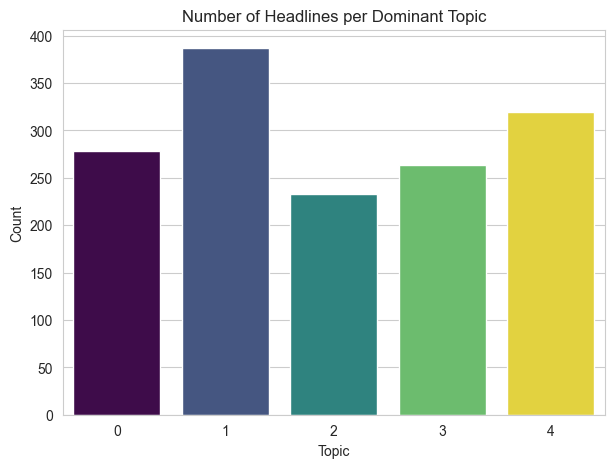

,Headlines,dominant_topic
123,FDA Commissioner Addresses H1N1 Vaccine Safety Concerns,1
432,Meningococcal Conjugate Vaccine Appears Safe in Infants,2
1031,Should Europe Be Worried About Zika Virus This Summer?,4
529,More Data Showing Flu Vaccine Lowers CVD Risk,0
1415,New York City Defends Measles Vaccination Order in Court,1
628,CDC Announces False Alarm on MERS Transmission,3
297,Flu Vaccine Rates Are High for 2 Seasons in a Row,4
1473,California Vaccine Bill Amended to Appease Governor,4
67,HPV Vaccination of Males Not Cost-Effective,3
49,Nonadjuvanted Influenza Vaccines May Not Protect Against 2009 H1N1,0


In [18]:
def get_dominant_topic(bow):
    topic_probs = lda_model.get_document_topics(bow)
    return max(topic_probs, key=lambda x: x[1])[0] if topic_probs else None

df["dominant_topic"] = [get_dominant_topic(bow) for bow in corpus]

plt.figure(figsize=(7, 5))
sns.countplot(x="dominant_topic", data=df, hue="dominant_topic", palette="viridis", legend=False)
plt.title("Number of Headlines per Dominant Topic")
plt.xlabel("Topic")
plt.ylabel("Count")
plt.show()

df[["Headlines", "dominant_topic"]].sample(10, random_state=RANDOM_STATE)
